# Выявление всплесков обращений клиентов RUDATA

НАЗВАНИЕ ПРОЕКТА: Интеллектуальная классификация и анализ клиентских обращений (задача 2.2.3), блок «всплески»

ОПИСАНИЕ. После классификации система отслеживает, сколько обращений приходит по каждому интерфейсу,
продукту, тематике и их сочетаниям. Если по какому-то значению за день пришло нетипично много обращений,
формируется уведомление: окно, признак, текущее количество и обычный уровень. Так поддержка узнаёт о сбое
или массовой проблеме по росту обращений, не дожидаясь, пока это заметит оператор.

Требования из описания данных:
- поток обрабатывается в порядке поступления; день без обращений — это ноль, а не пропуск;
- обычный уровень считается **только по прошлому**: будущее для нормы не используется;
- в начале истории нужен период накопления нормы, в нём уведомлений нет;
- нужно показать и найденные всплески, и ложные срабатывания;
- оценивать отдельно механизм на эталонной разметке и сквозной сценарий на предсказанных классах.

## Перевод задачи на язык анализа данных

Вид задачи: поиск аномалий во временных рядах, без учителя — флагов и расписания инцидентов в данных нет

Объект: пара «день × значение признака», например «9 сентября, тематика PERFORMANCE»

Что считаем: число обращений за день по каждому значению

Признаки, по которым ищем всплески:
- каждое поле отдельно: интерфейс, продукт, тематика;
- сочетания «интерфейс × тематика» и «продукт × тематика» — они точнее показывают, что именно случилось:
  не просто «много обращений про API», а «много жалоб на скорость API».

Окно: календарный день. Когда день закончился, его число сравнивается с нормой.

Норма: среднее число обращений за 28 предыдущих дней **того же типа** — будни сравниваются с буднями,
выходные с выходными.

## Загрузка необходимых библиотек

In [1]:
# Общее
import pandas as pd  # работа с датафреймами
import numpy as np  # математика
from matplotlib import pyplot as plt  # графики
import json  # прогнозы языковой модели
import math  # вероятность по распределению Пуассона

pd.set_option('display.max_colwidth', 200)  # показываем тексты обращений целиком

Константы

In [2]:
FIELDS = ['interface', 'product', 'topic']
FEATURES = [['interface'], ['product'], ['topic'], ['interface', 'topic'], ['product', 'topic']]  # что отслеживаем

BASELINE_DAYS = 28  # норма — по 28 предыдущим дням
WARMUP_DAYS = 28  # первые 28 дней истории — накопление нормы, без уведомлений

MIN_COUNT = 10  # всплеск — не меньше 10 обращений за день
MIN_RATIO = 2  # и хотя бы вдвое больше нормы
ALPHA = 0.0001  # и вероятность получить столько случайно при обычном уровне — меньше 0,01%
MIN_BASELINE = 0.5  # если в норме почти ноль, считаем её равной 0,5 обращения в день — чтобы не делить на ноль

## Загрузка данных

In [3]:
appeals = pd.read_csv('data/raw/appeals.csv', encoding='utf-8-sig', parse_dates=['created_at'])
appeals['date'] = appeals['created_at'].dt.tz_convert('Europe/Moscow').dt.date  # день поступления по Москве

# полный календарь: день без обращений тоже входит в поток — с нулём
days = list(pd.date_range(appeals['date'].min(), appeals['date'].max()).date)
alerts_start = days[WARMUP_DAYS]

display(f'Обращений {len(appeals)}, дней {len(days)}: {days[0]} — {days[-1]}')
display(f'Накопление нормы: {days[0]} — {days[WARMUP_DAYS - 1]}, уведомления — с {alerts_start}')

'Обращений 4765, дней 183: 2026-04-01 — 2026-09-30'

'Накопление нормы: 2026-04-01 — 2026-04-28, уведомления — с 2026-04-29'

## Поток обращений по дням

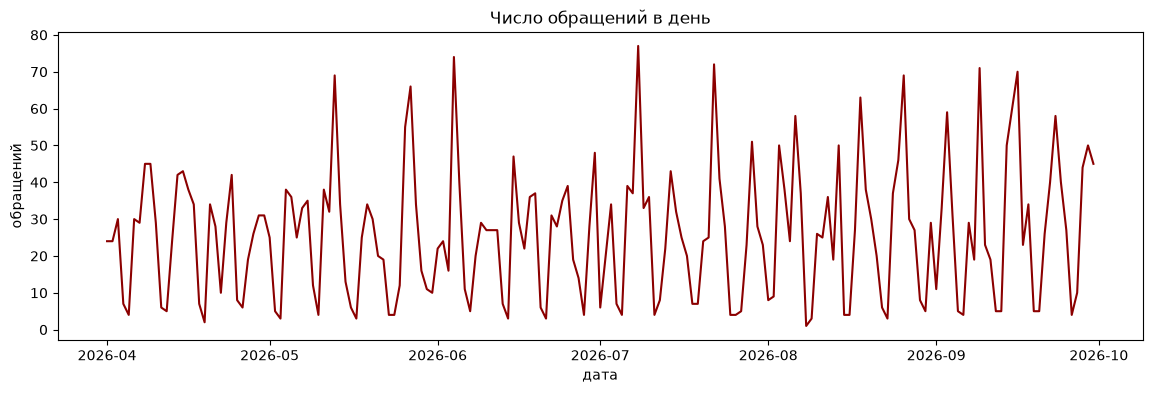

In [4]:
daily = appeals.groupby('date').size().reindex(days, fill_value=0)

daily.plot(figsize=(14, 4), color='darkred')
plt.title('Число обращений в день')
plt.xlabel('дата')
plt.ylabel('обращений')
plt.show()

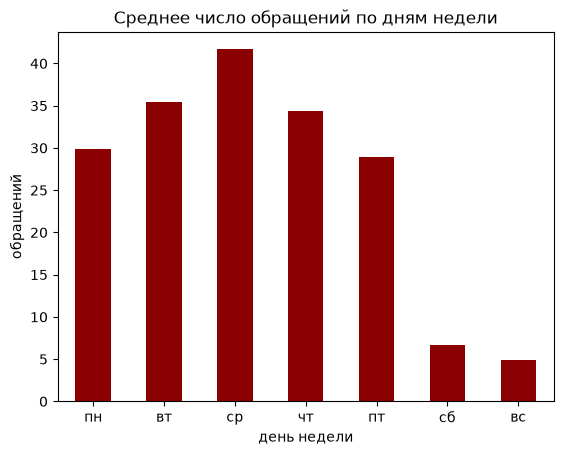

пн    29.8
вт    35.4
ср    41.7
чт    34.3
пт    28.9
сб     6.6
вс     4.9
dtype: float64

In [5]:
weekday_names = ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс']
by_weekday = daily.groupby([weekday_names[d.weekday()] for d in daily.index]).mean().reindex(weekday_names)

by_weekday.plot(kind='bar', color='darkred')
plt.title('Среднее число обращений по дням недели')
plt.xlabel('день недели')
plt.ylabel('обращений')
plt.xticks(rotation=0)
plt.show()

by_weekday.round(1)

**Вывод:** в будни приходит 29–42 обращения в день, в выходные — 5–7. Если сравнивать понедельник
с нормой, в которую входят выходные, каждый понедельник будет выглядеть всплеском. Поэтому норма считается
отдельно для будней и для выходных

## Метод

**Шаг 1. Число обращений по дням.** Для каждого значения признака — таблица «день × значение».
Дни без обращений заполняем нулями

In [6]:
def daily_counts(data, feature):
    # значение признака: одно поле («API») или сочетание полей («API × PERFORMANCE»)
    value = data[feature].astype(str).agg(' × '.join, axis=1)
    return data.groupby([data['date'], value]).size().unstack(fill_value=0).reindex(days_of(data), fill_value=0)


def days_of(data):
    return [day for day in days if data['date'].min() <= day <= data['date'].max()]


daily_counts(appeals, ['topic']).head()

,AUTH_ACCESS,AVAILABILITY,CONFIG_INTEGRATION,CONTRACT,DATA_DISCREPANCY,DATA_MISSING,FEATURE_REQUEST,FOLLOW_UP,HOW_TO,INSTALL_UPDATE,METHODOLOGY,PERFORMANCE,UNKNOWN
date,,,,,,,,,,,,,
2026-04-01,3,3,1,1,1,3,1,1,4,0,3,2,1
2026-04-02,2,1,2,2,1,1,3,0,3,0,2,6,1
2026-04-03,3,5,3,1,1,8,2,0,2,1,1,3,0
2026-04-04,3,0,0,0,0,0,1,0,0,0,1,1,1
2026-04-05,0,0,1,1,0,0,0,0,0,0,1,1,0


**Шаг 2. Норма — только по прошлому.** Для каждого дня берём 28 предыдущих дней, оставляем из них дни
того же типа (будни или выходные) и считаем среднее. Сам день и всё, что после него, в норму не входят

In [7]:
def baseline(counts):
    norm = pd.DataFrame(np.nan, index=counts.index, columns=counts.columns)
    for i, day in enumerate(counts.index):
        past = counts.index[max(0, i - BASELINE_DAYS):i]  # только предыдущие дни
        same_type = [d for d in past if (d.weekday() >= 5) == (day.weekday() >= 5)]  # будни с буднями, выходные с выходными
        if same_type:
            norm.loc[day] = counts.loc[same_type].mean()
    return norm

**Шаг 3. Нетипично ли много.** Число обращений колеблется само по себе: если обычно приходит 2 в день,
то 4 — вполне обычный день. Чтобы отличить случайное колебание от всплеска, используем распределение
Пуассона — стандартную модель для числа событий за период. Оно отвечает на вопрос: **какова вероятность
получить столько обращений или больше, если в среднем их столько, сколько в норме?**

Например, при норме 2 обращения в день вероятность получить 4 или больше — около 14% (обычный день),
а 10 или больше — около 0,005% (всплеск).

Уведомление формируется, если выполнены все три условия:
- за день не меньше `MIN_COUNT` = 10 обращений — единичные колебания малых значений не важны для поддержки;
- обращений хотя бы в `MIN_RATIO` = 2 раза больше нормы;
- вероятность получить столько случайно меньше `ALPHA` = 0,01%.

In [8]:
def poisson_tail(count, rate):
    """Вероятность получить count или больше обращений, если в среднем их rate"""
    below = sum(math.exp(-rate) * rate ** k / math.factorial(k) for k in range(count))
    return max(0.0, 1 - below)


display(f'Норма 2 в день: P(≥4) = {poisson_tail(4, 2):.1%}, P(≥10) = {poisson_tail(10, 2):.4%}')

'Норма 2 в день: P(≥4) = 14.3%, P(≥10) = 0.0046%'

In [9]:
def detect(data, start, alpha=ALPHA, min_count=MIN_COUNT):
    rows = []
    for feature in FEATURES:
        counts = daily_counts(data, feature)
        norm = baseline(counts)
        for day in [d for d in counts.index if d >= start]:
            for value in counts.columns:
                count, usual = int(counts.at[day, value]), norm.at[day, value]
                rate = max(usual, MIN_BASELINE)
                if count >= min_count and count >= MIN_RATIO * rate:
                    p_value = poisson_tail(count, rate)
                    if p_value < alpha:
                        rows.append({'date': day, 'feature': ' × '.join(feature), 'value': value, 'count': count,
                                     'usual': round(usual, 1), 'ratio': round(count / rate, 1), 'p_value': p_value})
    return pd.DataFrame(rows)


def notification(alert):
    usual = 'меньше 1' if alert['usual'] < 1 else f'{alert["usual"]:.1f}'.replace('.', ',')
    ratio = f'{alert["ratio"]:g}'.replace('.', ',')
    return (f'{alert["date"]:%d.%m.%Y} | {alert["feature"]} = {alert["value"]}: обращений за день — {alert["count"]}, '
            f'обычно {usual} в день, в {ratio} раза больше нормы')

## Всплески на эталонной разметке

Сначала проверяем сам механизм — на правильных метках из разметки, без ошибок классификации

In [10]:
alerts = detect(appeals, alerts_start)

display(f'Уведомлений: {len(alerts)}, дней с уведомлениями: {alerts["date"].nunique()}')
alerts.groupby('feature').size()

'Уведомлений: 63, дней с уведомлениями: 15'

feature
interface            13
interface × topic    14
product              12
product × topic      12
topic                12
dtype: int64

Один инцидент обычно поднимает сразу несколько признаков: например, сбой API в один день даёт всплеск
и по интерфейсу API, и по продукту NO_PRODUCT, и по сочетанию «API × PERFORMANCE». Поэтому смотрим сводку
по дням: самое точное уведомление за день — сочетание, если оно сработало, иначе отдельное поле

In [11]:
summary = (alerts.assign(is_combination=alerts['feature'].str.contains('×'))
           .sort_values(['is_combination', 'ratio'], ascending=False)
           .groupby('date').head(1).sort_values('date'))
summary[['date', 'feature', 'value', 'count', 'usual', 'ratio']]

,date,feature,value,count,usual,ratio
51,2026-05-13,product × topic,RD_SCORE × DATA_MISSING,40,0.4,80.0
1,2026-05-27,interface,API,14,3.7,3.8
38,2026-06-04,interface × topic,EXCEL_ADDIN × DATA_MISSING,35,0.4,70.0
39,2026-07-08,interface × topic,API × DATA_MISSING,46,1.2,36.8
40,2026-07-22,interface × topic,EFIR × AUTH_ACCESS,31,0.5,62.0
41,2026-08-03,interface × topic,EXCEL_TEMPLATE × METHODOLOGY,11,0.0,22.0
42,2026-08-04,interface × topic,EXCEL_TEMPLATE × HOW_TO,10,0.2,20.0
43,2026-08-06,interface × topic,WEB × PERFORMANCE,38,0.0,76.0
44,2026-08-18,interface × topic,WEB × AUTH_ACCESS,45,0.6,75.0
45,2026-08-26,interface × topic,EXCEL_ADDIN × AUTH_ACCESS,32,1.0,30.5


Уведомления в том виде, в каком их получит поддержка

In [12]:
for _, alert in summary.iterrows():
    print(notification(alert))

13.05.2026 | product × topic = RD_SCORE × DATA_MISSING: обращений за день — 40, обычно меньше 1 в день, в 80 раза больше нормы
27.05.2026 | interface = API: обращений за день — 14, обычно 3,7 в день, в 3,8 раза больше нормы
04.06.2026 | interface × topic = EXCEL_ADDIN × DATA_MISSING: обращений за день — 35, обычно меньше 1 в день, в 70 раза больше нормы
08.07.2026 | interface × topic = API × DATA_MISSING: обращений за день — 46, обычно 1,2 в день, в 36,8 раза больше нормы
22.07.2026 | interface × topic = EFIR × AUTH_ACCESS: обращений за день — 31, обычно меньше 1 в день, в 62 раза больше нормы
03.08.2026 | interface × topic = EXCEL_TEMPLATE × METHODOLOGY: обращений за день — 11, обычно меньше 1 в день, в 22 раза больше нормы
04.08.2026 | interface × topic = EXCEL_TEMPLATE × HOW_TO: обращений за день — 10, обычно меньше 1 в день, в 20 раза больше нормы
06.08.2026 | interface × topic = WEB × PERFORMANCE: обращений за день — 38, обычно меньше 1 в день, в 76 раза больше нормы
18.08.2026 | 

Как выглядят всплески на графике: число обращений по сочетанию по дням, норма и дни с уведомлениями

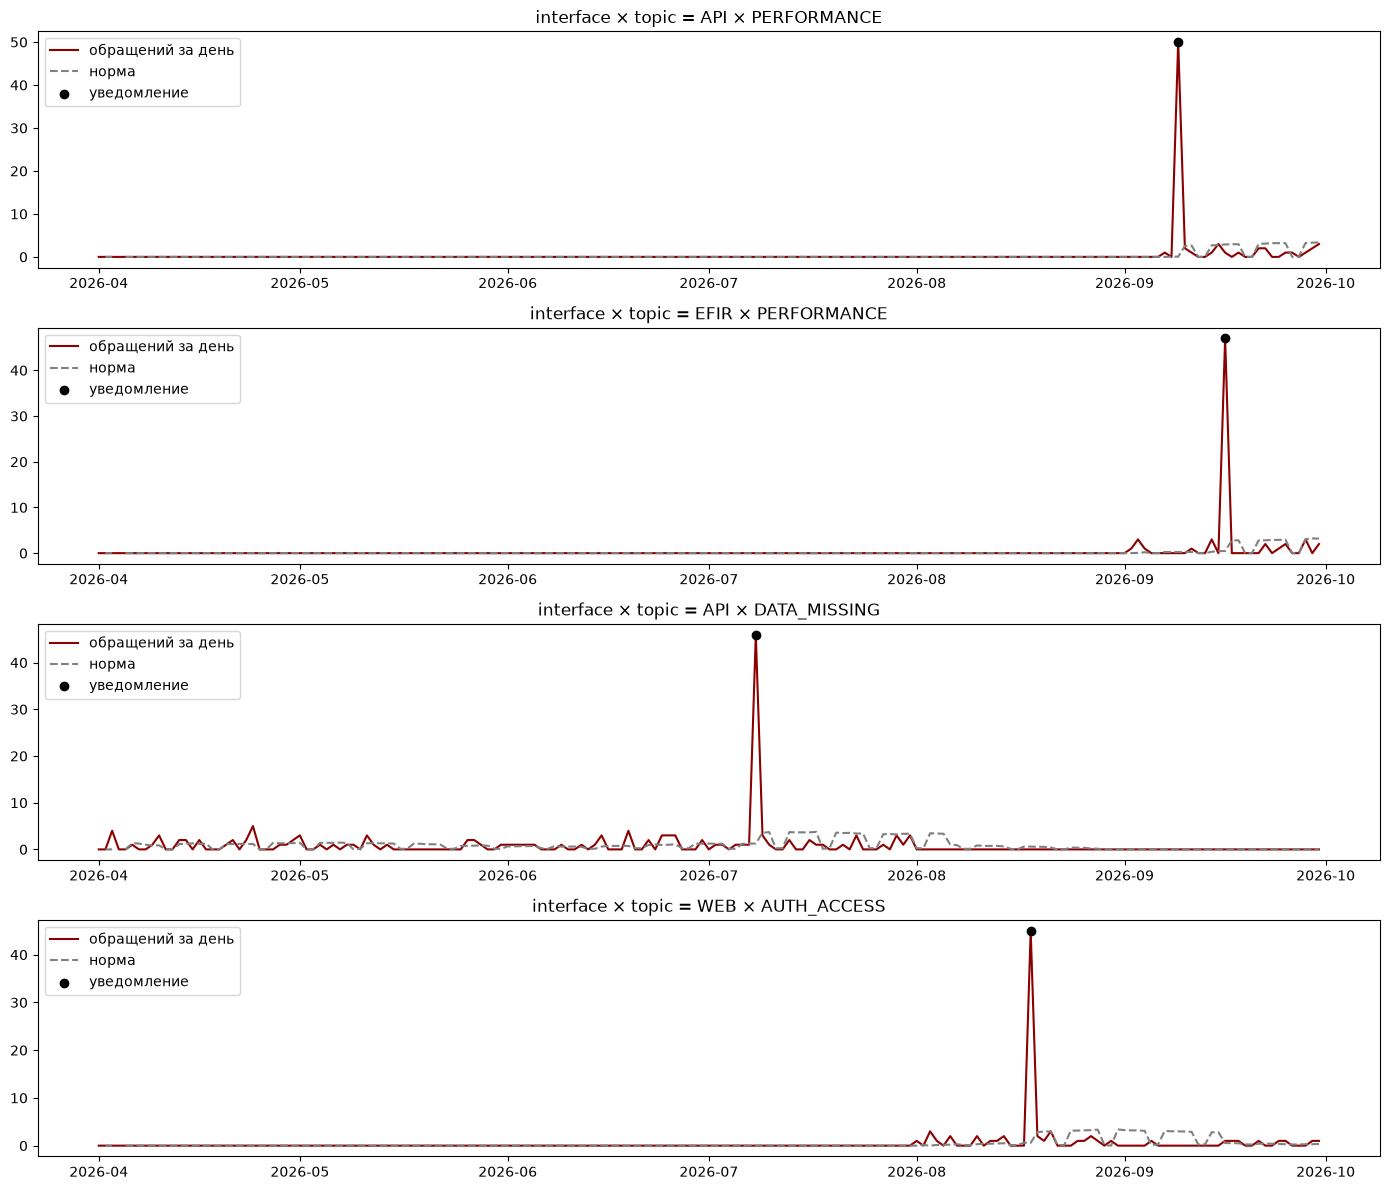

In [13]:
examples = summary.sort_values('count', ascending=False).head(4)

fig, axes = plt.subplots(nrows=len(examples), ncols=1, figsize=(14, 3 * len(examples)))
for ax, (_, alert) in zip(axes, examples.iterrows()):
    feature = alert['feature'].split(' × ')
    counts = daily_counts(appeals, feature)[alert['value']]
    norm = baseline(daily_counts(appeals, feature))[alert['value']]
    ax.plot(counts.index, counts.values, color='darkred', label='обращений за день')
    ax.plot(norm.index, norm.values, color='grey', linestyle='--', label='норма')
    hits = alerts[(alerts['feature'] == alert['feature']) & (alerts['value'] == alert['value'])]
    ax.scatter(hits['date'], hits['count'], color='black', zorder=3, label='уведомление')
    ax.set_title(f'{alert["feature"]} = {alert["value"]}')
    ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Что стоит за всплеском: обращения самого крупного из них

In [14]:
top = summary.sort_values('count', ascending=False).iloc[0]
feature = top['feature'].split(' × ')
in_spike = appeals[(appeals['date'] == top['date'])
                   & (appeals[feature].astype(str).agg(' × '.join, axis=1) == top['value'])]
display(notification(top))
in_spike[['created_at', 'client_id', 'text']].head(5)

'09.09.2026 | interface × topic = API × PERFORMANCE: обращений за день — 50, обычно меньше 1 в день, в 100 раза больше нормы'

,created_at,client_id,text
4053,2026-09-09 10:09:11+03:00,rd_user_0147,"Добрый день.\nAPI RUDATA, наш программный клиент. Запрос истории цен всё же завершается успешно, но задержка выросла в несколько раз. Просим проверить время ответа.\nОтвет нужен для дальнейшей раб..."
4054,2026-09-09 10:11:27+03:00,rd_user_0125,"Здравствуйте.\n\nИнтеграция с RUDATA идёт через HTTP API. Раньше ответ по списку из 18 инструментов приходил быстро, теперь занимает 45 секунд. Код 200, JSON полный.\n\nВопрос возник в ходе подгот..."
4055,2026-09-09 10:15:35+03:00,rd_user_0224,"Интеграция с RUDATA идёт через HTTP API. Раньше ответ по списку из 8 инструментов приходил быстро, теперь занимает 45 секунд. Код 200, JSON полный. Уточнения можно прислать ответом на это сообщение."
4057,2026-09-09 10:26:35+03:00,rd_user_0172,"Отправляю HTTP-запросы к API RUDATA. Запрос истории цен всё же завершается успешно, но задержка выросла в несколько раз. Просим проверить время ответа. По возможности ответьте в этой переписке."
4058,2026-09-09 10:27:33+03:00,rd_user_0114,"Работаем с REST API RUDATA. Запрос истории цен всё же завершается успешно, но задержка выросла в несколько раз. Просим проверить время ответа."


### Ложные срабатывания

Флагов заложенных инцидентов в данных нет, поэтому полноту обнаружения доказать нельзя. Но можно оценить,
сколько срабатываний ожидается **чисто случайно**. Каждая пара «день × значение» — одна проверка.
Если всплеска нет, каждая проверка случайно срабатывает с вероятностью не больше `ALPHA`, поэтому
ожидаемое число ложных срабатываний — не больше «число проверок × ALPHA»

In [15]:
n_checks = sum(daily_counts(appeals, feature).shape[1] for feature in FEATURES) * len([d for d in days if d >= alerts_start])
display(f'Проверок за период: {n_checks}, ожидаемо случайных срабатываний — не больше {n_checks * ALPHA:.1f}')

'Проверок за период: 25265, ожидаемо случайных срабатываний — не больше 2.5'

Как меняется результат при других настройках. При уровне 0,1% проверок так много, что около 25
срабатываний ожидаются просто по случайности — поэтому выбран уровень 0,01%

In [16]:
sensitivity = []
for alpha, min_count in [(0.001, 5), (0.0001, 5), (0.0001, 10), (0.00001, 10)]:
    found = detect(appeals, alerts_start, alpha=alpha, min_count=min_count)
    sensitivity.append({'alpha': alpha, 'min_count': min_count, 'alerts': len(found), 'days': found['date'].nunique(),
                        'expected_random': round(n_checks * alpha, 1)})

pd.DataFrame(sensitivity)

,alpha,min_count,alerts,days,expected_random
0,0.00100,5,85,22,25.3
1,0.00010,5,68,18,2.5
2,0.00010,10,63,15,2.5
3,0.00001,10,62,15,0.3


Самые слабые из найденных всплесков — кандидаты в ложные срабатывания

In [17]:
alerts.sort_values('count').head(6)[['date', 'feature', 'value', 'count', 'usual', 'ratio']]

,date,feature,value,count,usual,ratio
42,2026-08-04,interface × topic,EXCEL_TEMPLATE × HOW_TO,10,0.2,20.0
41,2026-08-03,interface × topic,EXCEL_TEMPLATE × METHODOLOGY,11,0.0,22.0
1,2026-05-27,interface,API,14,3.7,3.8
62,2026-09-29,product × topic,NO_PRODUCT × DATA_DISCREPANCY,21,1.6,13.5
50,2026-09-29,interface × topic,API × DATA_DISCREPANCY,21,0.9,23.3
36,2026-09-29,topic,DATA_DISCREPANCY,21,1.6,13.5


## Сквозной сценарий: всплески на предсказанных классах

В работе система видит не эталонные метки, а прогнозы классификатора. Ошибки классификации могут перенести
всплеск в другую категорию или создать ложный. Проверяем на прогнозах гибрида (подход 3 из `classify_llm.ipynb`):
интерфейс и продукт — бустинг, тематика — языковая модель; продукт `UNKNOWN`, если подходы разошлись.

Прогнозы есть только для августа и сентября (validation и test), поэтому август — период накопления нормы
по прогнозам, уведомления сравниваются за сентябрь

In [18]:
llm_params = json.load(open('models/llm_params.json', encoding='utf-8'))

rows = []
for split in ['validation', 'test']:
    classic = pd.read_csv(f'results/classic_predictions_{split}.csv', encoding='utf-8-sig', index_col='appeal_id')
    with open(f'results/llm_predictions_{split}.jsonl', encoding='utf-8') as f:
        for line in f:
            record = json.loads(line)
            row = classic.loc[record['appeal_id']]
            llm = record['answer']
            rows.append({'appeal_id': record['appeal_id'],
                         'interface': row['interface'],
                         'product': row['product'] if row['product'] == llm['product'] else 'UNKNOWN',
                         'topic': llm['topic']})

predicted = appeals[['appeal_id', 'date']].merge(pd.DataFrame(rows), on='appeal_id')
september = [d for d in days_of(predicted) if d.month == 9]

display(f'Прогнозов: {len(predicted)}, {predicted["date"].min()} — {predicted["date"].max()}; уведомления с {september[0]}')

'Прогнозов: 1735, 2026-08-01 — 2026-09-30; уведомления с 2026-09-01'

In [19]:
alerts_predicted = detect(predicted, september[0])
alerts_gold_september = alerts[alerts['date'] >= september[0]]


def alert_keys(data):
    return set(zip(data['date'], data['feature'], data['value']))


gold_keys, predicted_keys = alert_keys(alerts_gold_september), alert_keys(alerts_predicted)
display(f'Сентябрь: на эталоне {len(gold_keys)} уведомлений, на прогнозах {len(predicted_keys)}')
display(f'Совпали: {len(gold_keys & predicted_keys)}, пропущены: {len(gold_keys - predicted_keys)}, '
        f'лишние: {len(predicted_keys - gold_keys)}')

'Сентябрь: на эталоне 24 уведомлений, на прогнозах 26'

'Совпали: 24, пропущены: 0, лишние: 2'

In [20]:
extra = alerts_predicted[[(row.date, row.feature, row.value) not in gold_keys for row in alerts_predicted.itertuples()]]
missed = alerts_gold_september[[(row.date, row.feature, row.value) not in predicted_keys
                                for row in alerts_gold_september.itertuples()]]
display('Лишние уведомления (есть на прогнозах, нет на эталоне):')
display(extra[['date', 'feature', 'value', 'count', 'usual', 'ratio']])
display('Пропущенные (есть на эталоне, нет на прогнозах):')
display(missed[['date', 'feature', 'value', 'count', 'usual', 'ratio']])

'Лишние уведомления (есть на прогнозах, нет на эталоне):'

,date,feature,value,count,usual,ratio
16,2026-09-14,interface × topic,EXCEL_TEMPLATE × AVAILABILITY,13,3.3,3.9
17,2026-09-15,interface × topic,EXCEL_TEMPLATE × DATA_MISSING,12,3.0,3.9


'Пропущенные (есть на эталоне, нет на прогнозах):'

,date,feature,value,count,usual,ratio


Почему появились лишние уведомления: сравним для них число обращений и норму на эталоне и на прогнозах

In [21]:
for row in extra.itertuples():
    counts = daily_counts(appeals, row.feature.split(' × '))
    norm = baseline(counts)
    print(f'{row.date} {row.value}: на прогнозах — {row.count} обращений при норме {row.usual}; '
          f'на эталоне — {counts.at[row.date, row.value]} при норме {norm.at[row.date, row.value]:.1f}')

2026-09-14 EXCEL_TEMPLATE × AVAILABILITY: на прогнозах — 13 обращений при норме 3.3; на эталоне — 13 при норме 3.6
2026-09-15 EXCEL_TEMPLATE × DATA_MISSING: на прогнозах — 12 обращений при норме 3.0; на эталоне — 12 при норме 3.1


## Сохранение результатов

In [22]:
alerts.assign(notification=alerts.apply(notification, axis=1)).to_csv(
    'results/spikes_gold.csv', index=False, encoding='utf-8-sig')
alerts_predicted.assign(notification=alerts_predicted.apply(notification, axis=1)).to_csv(
    'results/spikes_predicted_september.csv', index=False, encoding='utf-8-sig')

## Выводы

- **Метод.** Окно — календарный день. Норма — среднее за 28 предыдущих дней того же типа (будни или выходные),
  только по прошлому; первые 28 дней истории — накопление нормы. Всплеск — не меньше 10 обращений за день,
  хотя бы вдвое больше нормы и вероятность получить столько случайно меньше 0,01% (распределение Пуассона).
  Отслеживаются отдельные поля и сочетания «интерфейс × тематика», «продукт × тематика».
- **Эталонная разметка, май–сентябрь:** 63 уведомления в 15 днях. В 12 днях — явные инциденты: 21–50 обращений
  по одному сочетанию при обычных 0–1 в день. Например, 09.09 — 50 жалоб на скорость API, 16.09 — 47 жалоб
  на скорость ЭФИР, 18.08 — 45 проблем со входом на сайт.
- **Кандидаты в ложные срабатывания** — 3 более слабых уведомления: 27.05 (API — 14 обращений при норме 3,7),
  03.08 и 04.08 (10–11 вопросов по методологии и работе с шаблонами при норме около нуля). В начале августа
  меняется состав потока, а не происходит сбой. Это согласуется с оценкой: случайно за период ожидается
  не больше 2–3 срабатываний. При уровне 0,1% случайных срабатываний ожидалось бы около 25, поэтому выбран 0,01%.
- **Сквозной сценарий** (сентябрь, прогнозы гибрида): все 24 уведомления эталона воспроизведены, пропусков нет.
  Два лишних (14.09 и 15.09) — пограничные: число обращений то же, что на эталоне, а норма по прогнозам августа
  немного ниже эталонной.
- **Ограничения.** Флагов инцидентов в данных нет, поэтому полноту обнаружения подтвердить нельзя — только оценкой
  ожидаемого числа случайных срабатываний и разбором примеров. Окно в день сообщает о сбое по итогам дня;
  для более быстрой реакции нужно окно короче (например, час) с отдельно подобранными порогами.
  При росте потока или изменении его состава пороги нужно пересматривать.